# Image Processing Lab 6
## Filtering in the frequency domain


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import scipy
import skimage
from numpy.fft import fft2, ifft2, fftshift, ifftshift
from scipy.signal import convolve2d
from skimage import data
from skimage.transform import resize

print("NumPy:", np.__version__)
print("scikit-image:", skimage.__version__)
print("SciPy:", scipy.__version__)


NumPy: 2.5.4
scikit-image: 0.26.0
SciPy: 1.18.1


## Shared input image

Load the grayscale Cameraman image and resize it to 256 × 256 pixels, as in the manual. `resize` converts the original unsigned-byte intensities to floating-point values in [0, 1]. The same array is used for both tasks.

In [ ]:
original_image = data.camera()
image = resize(original_image, (256, 256), anti_aliasing=True)
M, N = image.shape
F = fft2(image)

assert original_image.ndim == 2
assert image.shape == (256, 256)
assert np.isfinite(image).all()
assert 0 <= image.min() <= image.max() <= 1
assert np.allclose(ifft2(F).real, image, atol=1e-12, rtol=0)

print("Original shape:", original_image.shape)
print("Working shape:", image.shape)
print(f"Intensity range: [{image.min():.6f}, {image.max():.6f}]")


Original shape: (512, 512)
Working shape: (256, 256)
Intensity range: [0.008466, 0.999493]


## Procedural task 1 — Laplacian filtering

For row and column frequencies $u$ and $v$ in cycles per pixel, use the transfer function supplied in the manual:

$$H_L(u,v)=-4\pi^2(u^2+v^2),\qquad G_L=F H_L,\qquad g_L=\operatorname{Re}\{\mathcal F^{-1}(G_L)\}.$$

`fftfreq` produces frequencies in the order required by the unshifted FFT. This ordering is retained during multiplication. The spectrum panel below follows the manual's unshifted display. The Laplacian response is signed, so zero is shown at mid-gray using symmetric intensity limits.

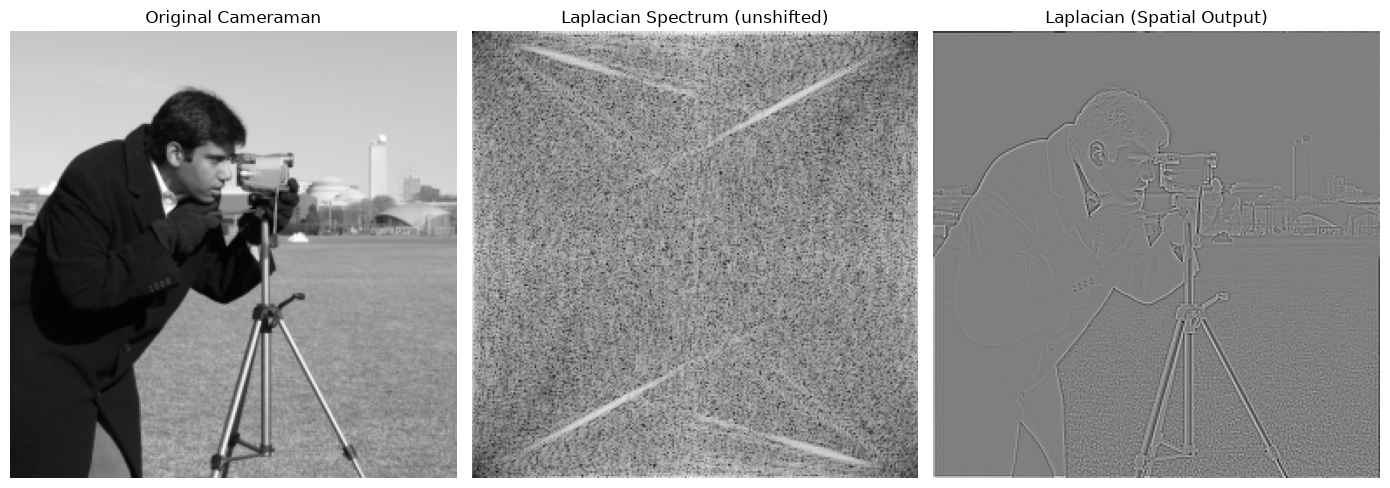

Laplacian response range: [-2.037387, 1.941461]


In [ ]:
u = np.fft.fftfreq(M).reshape(-1, 1)
v = np.fft.fftfreq(N).reshape(1, -1)
laplacian_filter = -4 * np.pi**2 * (u**2 + v**2)
F_lap = F * laplacian_filter
laplacian_complex = ifft2(F_lap)
laplacian_image = laplacian_complex.real

assert laplacian_filter[0, 0] == 0
assert np.max(np.abs(laplacian_complex.imag)) < 1e-12
assert np.isfinite(laplacian_image).all()
assert abs(laplacian_image.mean()) < 1e-12

laplacian_limit = np.max(np.abs(laplacian_image))
fig, axes = plt.subplots(1, 3, figsize=(14, 4.8))
axes[0].imshow(image, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Original Cameraman")
axes[1].imshow(np.log1p(np.abs(F_lap)), cmap="gray")
axes[1].set_title("Laplacian Spectrum (unshifted)")
axes[2].imshow(laplacian_image, cmap="gray", vmin=-laplacian_limit, vmax=laplacian_limit)
axes[2].set_title("Laplacian (Spatial Output)")
for ax in axes:
    ax.axis("off")
fig.tight_layout()
plt.show()

print(f"Laplacian response range: [{laplacian_image.min():.6f}, {laplacian_image.max():.6f}]")


### Laplacian result

The Laplacian emphasizes rapid intensity changes and suppresses constant regions because its zero-frequency gain is zero. Bright and dark outlines in the spatial output represent positive and negative second-derivative responses. Multiplication of same-sized FFTs imposes periodic boundaries, so transitions between opposite image borders can also produce responses.

## Assessment task 1 — Sobel filtering in the frequency domain

Use both 3 × 3 kernels exactly as supplied in the assessment. The provided `center_embed_kernel` procedure embeds each kernel at the image center, moves its origin to index (0, 0) with `ifftshift`, and computes its FFT. This avoids a spatial displacement of the filtered image.

$$G_x=F H_x,\qquad G_y=F H_y,$$
$$g_x=\operatorname{Re}\{\mathcal F^{-1}(G_x)\},\qquad g_y=\operatorname{Re}\{\mathcal F^{-1}(G_y)\},$$
$$g=\sqrt{g_x^2+g_y^2}.$$

These products implement circular convolution with the supplied kernels. Correlation-based implementations can use the opposite sign for the directional responses; the combined magnitude is unchanged by reversing both signs.

In [ ]:
sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]], dtype=float)
sobel_y = np.array([[-1, -2, -1],
                    [0, 0, 0],
                    [1, 2, 1]], dtype=float)

def center_embed_kernel(kernel, shape):
    padded = np.zeros(shape)
    kh, kw = kernel.shape
    ph, pw = shape
    cy, cx = ph // 2, pw // 2
    padded[cy - kh // 2:cy - kh // 2 + kh,
           cx - kw // 2:cx - kw // 2 + kw] = kernel
    return fft2(ifftshift(padded))

H_x = center_embed_kernel(sobel_x, image.shape)
H_y = center_embed_kernel(sobel_y, image.shape)
F_sobel_x = F * H_x
F_sobel_y = F * H_y
sobel_x_complex = ifft2(F_sobel_x)
sobel_y_complex = ifft2(F_sobel_y)
sobel_x_image = sobel_x_complex.real
sobel_y_image = sobel_y_complex.real
sobel_magnitude = np.hypot(sobel_x_image, sobel_y_image)

print("Sobel x kernel:")
print(sobel_x)
print("Sobel y kernel:")
print(sobel_y)


Sobel x kernel:
[[-1.  0.  1.]
 [-2.  0.  2.]
 [-1.  0.  1.]]
Sobel y kernel:
[[-1. -2. -1.]
 [ 0.  0.  0.]
 [ 1.  2.  1.]]


### Frequency-domain results

`fftshift` is used only for visualization here, placing zero frequency at the center of each panel. The top row shows the two filter transfer magnitudes; the bottom row shows the filtered image spectra. `log1p` makes a broad range of spectral magnitudes visible without taking the logarithm of zero.

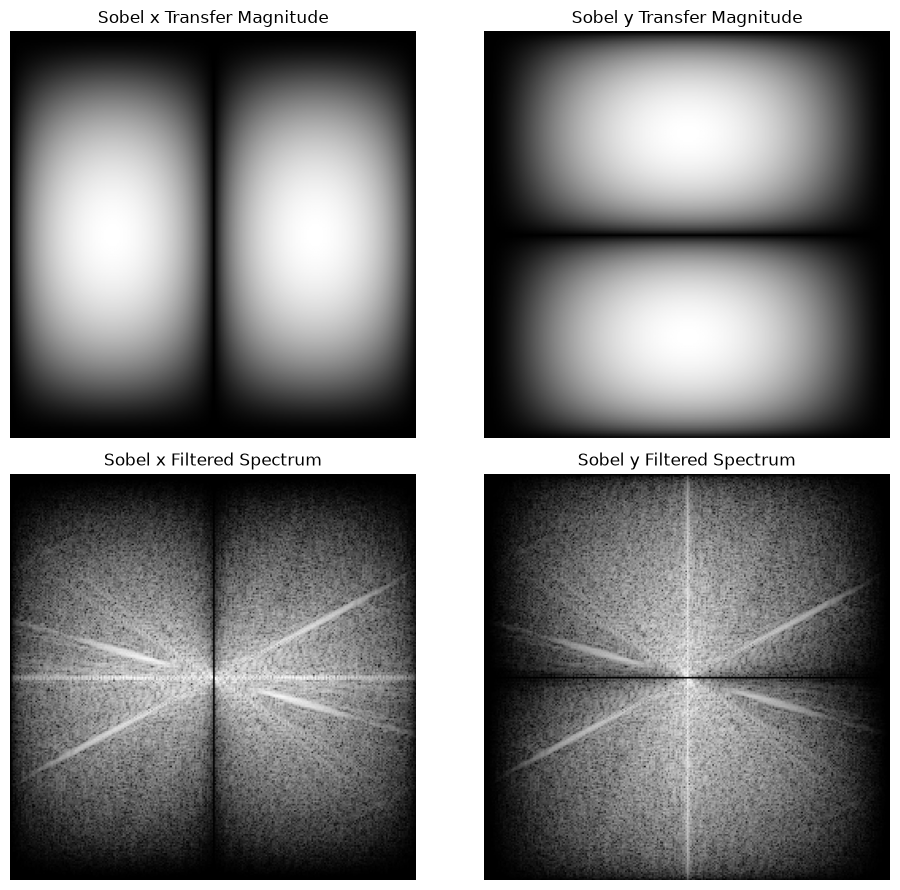

In [ ]:
spectra = [
    (H_x, "Sobel x Transfer Magnitude"),
    (H_y, "Sobel y Transfer Magnitude"),
    (F_sobel_x, "Sobel x Filtered Spectrum"),
    (F_sobel_y, "Sobel y Filtered Spectrum")
]
fig, axes = plt.subplots(2, 2, figsize=(10, 9))
for ax, (spectrum, title) in zip(axes.ravel(), spectra):
    ax.imshow(np.log1p(np.abs(fftshift(spectrum))), cmap="gray")
    ax.set_title(title)
    ax.axis("off")
fig.tight_layout()
plt.show()


### Spatial Sobel results

The x response emphasizes intensity changes across columns, making vertical edges prominent. The y response emphasizes changes across rows, making horizontal edges prominent. Both signed responses share the same symmetric display scale. Their Euclidean magnitude combines the two directions into a nonnegative edge-strength image. All filtering above is performed by multiplication in the frequency domain.

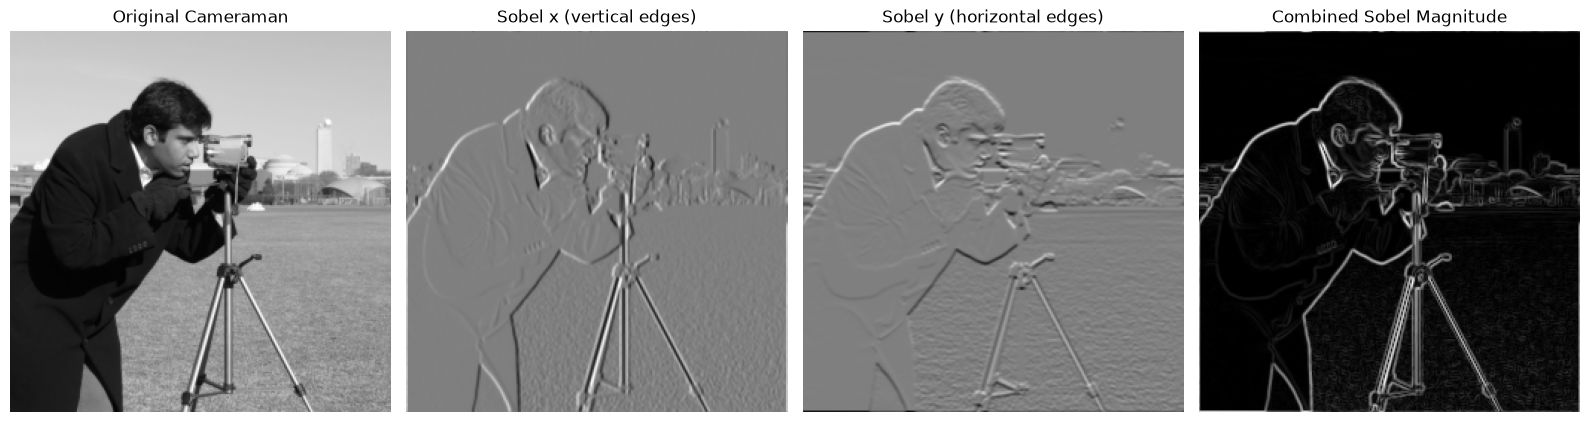

In [ ]:
directional_limit = max(np.max(np.abs(sobel_x_image)), np.max(np.abs(sobel_y_image)))
fig, axes = plt.subplots(1, 4, figsize=(16, 4.6))
axes[0].imshow(image, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Original Cameraman")
axes[1].imshow(sobel_x_image, cmap="gray", vmin=-directional_limit, vmax=directional_limit)
axes[1].set_title("Sobel x (vertical edges)")
axes[2].imshow(sobel_y_image, cmap="gray", vmin=-directional_limit, vmax=directional_limit)
axes[2].set_title("Sobel y (horizontal edges)")
axes[3].imshow(sobel_magnitude, cmap="gray", vmin=0, vmax=sobel_magnitude.max())
axes[3].set_title("Combined Sobel Magnitude")
for ax in axes:
    ax.axis("off")
fig.tight_layout()
plt.show()


## Numerical verification

Compare the two FFT-based Sobel outputs with independent spatial convolution using `convolve2d` and wraparound boundaries, matching the periodic boundary convention of the FFT. Also check the reconstruction, array sizes, imaginary residuals, zero DC response and finite values. Spatial convolution is used only to verify the frequency-domain solution.

In [ ]:
spatial_x = convolve2d(image, sobel_x, mode="same", boundary="wrap")
spatial_y = convolve2d(image, sobel_y, mode="same", boundary="wrap")
error_x = np.max(np.abs(sobel_x_image - spatial_x))
error_y = np.max(np.abs(sobel_y_image - spatial_y))

assert np.allclose(sobel_x_image, spatial_x, atol=1e-12, rtol=0)
assert np.allclose(sobel_y_image, spatial_y, atol=1e-12, rtol=0)
assert np.max(np.abs(sobel_x_complex.imag)) < 1e-12
assert np.max(np.abs(sobel_y_complex.imag)) < 1e-12
assert abs(H_x[0, 0]) < 1e-12
assert abs(H_y[0, 0]) < 1e-12
assert np.allclose(np.hypot(spatial_x, spatial_y), sobel_magnitude, atol=1e-12, rtol=0)
for result in (laplacian_image, sobel_x_image, sobel_y_image, sobel_magnitude):
    assert result.shape == image.shape
    assert np.isfinite(result).all()

print(f"Maximum Sobel x error versus spatial convolution: {error_x:.3e}")
print(f"Maximum Sobel y error versus spatial convolution: {error_y:.3e}")
print("All numerical checks passed.")


Maximum Sobel x error versus spatial convolution: 1.776e-15
Maximum Sobel y error versus spatial convolution: 2.862e-15
All numerical checks passed.


## Conclusion

The procedural task applies the manual's Laplacian transfer function to the Cameraman image. The assessment applies both supplied Sobel kernels through FFT multiplication and inverse transformation. The displayed outputs include the Laplacian spectrum and response, both Sobel transfer functions and filtered spectra, both directional Sobel responses and their combined edge magnitude. Independent spatial convolution verifies the Sobel results to floating-point precision.

### References

- Supplied Student Procedural Manual, Lab 6: procedural task and assessment.
- [NumPy FFT documentation](https://numpy.org/doc/stable/reference/routines.fft.html)
- [scikit-image Cameraman dataset](https://scikit-image.org/docs/stable/api/skimage.data.html#skimage.data.camera)